In [ ]:
from pathlib import Path
import pandas as pd
import os

import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
import duckdb
from IPython.display import display
import re


# مرحله اول ـ بخش اول: شناسایی ساختار دیتاست
## ۲. بررسی اولیه هر دو فایل
## این کد اطلاعات اولیه را بدون بارگذاری کامل فایل‌ها استخراج می‌کند.

In [2]:
# پیدا کردن پوشه دیتاست
possible_paths = [
    Path("../data/digikala"),
    Path("data/digikala")
]

DATA_DIR = next(
    (p for p in possible_paths if p.exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("پوشه data/digikala پیدا نشد!")

# مسیر فایل‌ها
comments_path = DATA_DIR / "digikala-comments.csv"
products_path = DATA_DIR / "digikala-products.csv"

# بررسی وجود فایل‌ها
for path in [comments_path, products_path]:

    if not path.exists():
        raise FileNotFoundError(f"فایل پیدا نشد: {path}")

    print(f"File: {path.name}")
    print(f"Size: {os.path.getsize(path) / (1024**2):.2f} MB")
    print("-" * 50)

File: digikala-comments.csv
Size: 1219.30 MB
--------------------------------------------------
File: digikala-products.csv
Size: 246.75 MB
--------------------------------------------------


## ۳. مشاهده ستون‌ها و نمونه داده‌ها

In [3]:
def inspect_csv(path):

    print(f"\n{'='*60}")
    print(f"FILE: {path.name}")
    print(f"{'='*60}")

    # خواندن فقط 5 ردیف اول
    df = pd.read_csv(
        path,
        nrows=5,
        encoding="utf-8-sig"
    )

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nFirst 5 Rows:")
    display(df)

    print("\nMemory Usage:")
    print(df.memory_usage(deep=True).sum() / (1024**2), "MB")


inspect_csv(comments_path)
inspect_csv(products_path)


FILE: digikala-comments.csv

Columns:
['id', 'title', 'body', 'created_at', 'rate', 'recommendation_status', 'is_buyer', 'product_id', 'advantages', 'disadvantages', 'likes', 'dislikes', 'seller_title', 'seller_code', 'true_to_size_rate']

Data Types:
id                         int64
title                        str
body                         str
created_at                   str
rate                     float64
recommendation_status        str
is_buyer                    bool
product_id                 int64
advantages                   str
disadvantages                str
likes                      int64
dislikes                   int64
seller_title                 str
seller_code                  str
true_to_size_rate        float64
dtype: object

First 5 Rows:


,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,28 اسفند 1399,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,12 شهریور 1402,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN



Memory Usage:
0.0036249160766601562 MB

FILE: digikala-products.csv

Columns:
['id', 'title_fa', 'Rate', 'Rate_cnt', 'Category1', 'Category2', 'Brand', 'Price', 'Seller', 'Is_Fake', 'min_price_last_month', 'sub_category']

Data Types:
id                        int64
title_fa                    str
Rate                      int64
Rate_cnt                  int64
Category1                   str
Category2               float64
Brand                       str
Price                     int64
Seller                      str
Is_Fake                    bool
min_price_last_month      int64
sub_category                str
dtype: object

First 5 Rows:


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,NaN,متفرقه,634800,سلامت ساز راد,False,0,beauty
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,NaN,متفرقه,818800,مهر افزون,False,0,beauty
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,NaN,متفرقه,920000,یانگوم,False,0,beauty
3,1912926,استند ابسلانگ مدل S01,78,25,آبسلانگ,NaN,متفرقه,1100000,بهراد طب بیدار,False,0,beauty
4,6335462,آبسلانگ نوری تسلامد مدل All-in-One,84,25,آبسلانگ,NaN,تسلا مد,1530000,دیجی‌کالا,False,0,beauty



Memory Usage:
0.0023784637451171875 MB


## ۴. بررسی کامل تعداد رکوردها و مقادیر خالی
## حالا می‌خواهیم تمام فایل‌ها را بخش‌بخش بررسی کنیم.

### chunk_size=100_000 یعنی در هر مرحله حداکثر ۱۰۰ هزار ردیف خوانده می‌شود.

In [4]:
def analyze_csv_chunks(path, chunk_size=100_000):

    print(f"\nAnalyzing: {path.name}")

    total_rows = 0
    missing_counts = None

    # خواندن فایل به صورت بخش‌بخش
    for chunk in pd.read_csv(
        path,
        chunksize=chunk_size,
        encoding="utf-8-sig"
    ):

        total_rows += len(chunk)

        # شمارش مقادیر خالی
        current_missing = chunk.isna().sum()

        if missing_counts is None:
            missing_counts = current_missing
        else:
            missing_counts += current_missing

    # گزارش نهایی
    report = pd.DataFrame({
        "missing_count": missing_counts,
        "missing_percent": (
            missing_counts / total_rows
        ) * 100
    })

    print("\nTotal Rows:", f"{total_rows:,}")

    print("\nMissing Values:")
    display(report.sort_values(
        "missing_percent",
        ascending=False
    ))

    return total_rows, report


comments_rows, comments_missing = analyze_csv_chunks(
    comments_path
)

products_rows, products_missing = analyze_csv_chunks(
    products_path
)


Analyzing: digikala-comments.csv

Total Rows: 6,156,289

Missing Values:


,missing_count,missing_percent
true_to_size_rate,6065516,98.525524
disadvantages,5744017,93.303238
advantages,5448084,88.496235
title,2865062,46.538783
recommendation_status,894426,14.528655
seller_title,302181,4.908493
seller_code,302181,4.908493
body,637,0.010347
rate,0,0.000000
created_at,0,0.000000



Analyzing: digikala-products.csv

Total Rows: 1,283,496

Missing Values:


,missing_count,missing_percent
Category2,210108,16.369977
Seller,223,0.017374
id,0,0.000000
title_fa,0,0.000000
Rate_cnt,0,0.000000
Rate,0,0.000000
Brand,0,0.000000
Category1,0,0.000000
Price,0,0.000000
Is_Fake,0,0.000000


## ۵. بررسی ارتباط دو فایل
## فعلاً فقط چند نمونه از شناسه‌ها را می‌بینیم تا مشخص شود رابطه چگونه است.

### این مرحله فقط نمونه شناسه‌ها را نشان می‌دهد؛

In [5]:
# خواندن شناسه کامنت و شناسه محصول از فایل کامنت‌ها
comments_sample = pd.read_csv(
    comments_path,
    usecols=["id", "product_id"],
    nrows=20
)

# خواندن شناسه محصولات
products_sample = pd.read_csv(
    products_path,
    usecols=["id"],
    nrows=20
)

print("Comments:")
display(comments_sample)

print("Products:")
display(products_sample)

Comments:


,id,product_id
0,53672599,252058
1,9897229,252058
2,38074516,3331597
3,18628562,3331329
4,53301258,3255700
5,53266157,3305270
6,46206235,3480048
7,40597171,3480048
8,46198656,7626372
9,46901811,821812


Products:


,id
0,7096438
1,2845119
2,6117745
3,1912926
4,6335462
5,6335562
6,7096725
7,7096768
8,6005981
9,4077287


ادامه مرحله اول: تحلیل توزیع داده‌ها
حالا می‌خواهیم سه سؤال اساسی را پاسخ بدهیم:
1. چند کامنت مثبت، منفی و خنثی داریم؟
2. توزیع امتیازهای ۰ تا ۵ چگونه است؟
3. طول کامنت‌ها چقدر است؟

۱. کد تحلیل توزیع کلاس‌ها و امتیازها

In [6]:
# مسیر فایل کامنت‌ها
comments_path = DATA_DIR / "digikala-comments.csv"

# تنظیمات پردازش
CHUNK_SIZE = 100_000
SAMPLE_PER_CHUNK = 5_000

# شمارنده‌ها
recommendation_counts = Counter()
rate_counts = Counter()

total_rows = 0
missing_body = 0
missing_recommendation = 0
missing_rate = 0

# برای تحلیل طول کامنت‌ها
length_samples = []

# حداقل و حداکثر طول واقعی
min_length = float("inf")
max_length = 0

# خواندن بخش‌بخش فایل
for chunk in pd.read_csv(
    comments_path,
    usecols=["body", "rate", "recommendation_status"],
    chunksize=CHUNK_SIZE,
    encoding="utf-8-sig"
):

    total_rows += len(chunk)

    # -----------------------------
    # 1. Recommendation Distribution
    # -----------------------------

    recommendation = (
        chunk["recommendation_status"]
        .fillna("<MISSING>")
        .astype(str)
        .str.strip()
    )

    recommendation_counts.update(
        recommendation.value_counts().to_dict()
    )

    missing_recommendation += (
        chunk["recommendation_status"].isna().sum()
    )

    # -----------------------------
    # 2. Rate Distribution
    # -----------------------------

    rate = pd.to_numeric(
        chunk["rate"],
        errors="coerce"
    )

    rate_counts.update(
        rate.fillna("<INVALID>").astype(str).value_counts().to_dict()
    )

    missing_rate += rate.isna().sum()

    # -----------------------------
    # 3. Comment Length
    # -----------------------------

    body = chunk["body"].fillna("").astype(str)

    lengths = body.str.len()

    missing_body += chunk["body"].isna().sum()

    if len(lengths) > 0:
        min_length = min(min_length, lengths.min())
        max_length = max(max_length, lengths.max())

    # نمونه‌گیری برای محاسبه تقریبی توزیع طول
    length_samples.append(
        lengths.sample(
            n=min(SAMPLE_PER_CHUNK, len(lengths)),
            random_state=42
        )
    )


print("Total Comments:", f"{total_rows:,}")

# -----------------------------
# Recommendation Report
# -----------------------------

recommendation_report = pd.DataFrame(
    recommendation_counts.items(),
    columns=["class", "count"]
)

recommendation_report["percentage"] = (
    recommendation_report["count"] / total_rows * 100
)

print("\nRecommendation Distribution:")
display(
    recommendation_report.sort_values(
        "count",
        ascending=False
    )
)

# -----------------------------
# Rate Report
# -----------------------------

rate_report = pd.DataFrame(
    rate_counts.items(),
    columns=["rate", "count"]
)

print("\nRate Distribution:")
display(
    rate_report.sort_values(
        "rate",
        ascending=True
    )
)

# -----------------------------
# Comment Length Report
# -----------------------------

all_lengths = pd.concat(
    length_samples,
    ignore_index=True
)

print("\nComment Length Statistics:")

print("Minimum:", min_length)
print("Maximum:", max_length)

display(
    all_lengths.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nMissing Body:", missing_body)
print("Missing Recommendation:", missing_recommendation)
print("Invalid or Missing Rate:", missing_rate)

Total Comments: 6,156,289

Recommendation Distribution:


,class,count,percentage
0,recommended,4162839,67.619291
1,<MISSING>,894426,14.528655
2,no_idea,594121,9.650635
3,not_recommended,504903,8.201418



Rate Distribution:


,rate,count
3,0.0,529098
98,0.05,97
88,0.1,66
94,0.15,181
67,0.2,661
...,...,...
17,4.8,7276
27,4.85,1476
170,4.88,2
65,4.9,426



Comment Length Statistics:
Minimum: 0
Maximum: 4000


count    310000.000000
mean         48.596097
std          65.341685
min           0.000000
25%          16.000000
50%          29.000000
75%          57.000000
90%         106.000000
95%         153.000000
99%         301.000000
max        4000.000000
Name: body, dtype: float64


Missing Body: 637
Missing Recommendation: 894426
Invalid or Missing Rate: 0


## ۶. قدم بعدی: محاسبه توزیع سه کلاس

,class,count,percentage
0,low,1092329,17.743306
1,medium,1059054,17.202801
2,high,4004905,65.053893


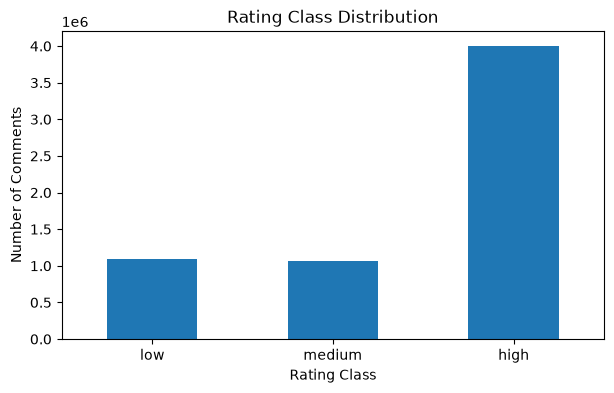

In [7]:
# شمارش تعداد هر کلاس
rating_class_counts = {
    "low": 0,
    "medium": 0,
    "high": 0
}

for chunk in pd.read_csv(
    comments_path,
    usecols=["rate"],
    chunksize=100_000
):

    rate = pd.to_numeric(chunk["rate"])

    rating_class_counts["low"] += (
        (rate >= 0) & (rate < 2.5)
    ).sum()

    rating_class_counts["medium"] += (
        (rate >= 2.5) & (rate < 4)
    ).sum()

    rating_class_counts["high"] += (
        (rate >= 4) & (rate <= 5)
    ).sum()


# ساخت جدول
rating_report = pd.DataFrame(
    rating_class_counts.items(),
    columns=["class", "count"]
)

rating_report["percentage"] = (
    rating_report["count"] /
    rating_report["count"].sum()
) * 100

display(rating_report)

# نمودار
rating_report.plot(
    x="class",
    y="count",
    kind="bar",
    legend=False,
    title="Rating Class Distribution",
    figsize=[7,4],
)

plt.ylabel("Number of Comments")
plt.xlabel("Rating Class")
plt.xticks(rotation=0)
plt.show()

## بررسی تعداد کامنت‌های هر محصول

In [8]:
product_comment_counts = {}

for chunk in pd.read_csv(
    comments_path,
    usecols=["product_id"],
    chunksize=100_000
):

    counts = chunk["product_id"].value_counts()

    for product_id, count in counts.items():
        product_comment_counts[product_id] = (
            product_comment_counts.get(product_id, 0) + count
        )

# تبدیل به DataFrame
product_stats = pd.DataFrame(
    product_comment_counts.items(),
    columns=["product_id", "comment_count"]
)

print("Total Products with Comments:", len(product_stats))

print("\nComment Count Statistics:")
display(product_stats["comment_count"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nTop 10 Products:")
display(
    product_stats.sort_values(
        "comment_count",
        ascending=False
    ).head(10)
)

Total Products with Comments: 331599

Comment Count Statistics:


count    331599.000000
mean         18.565463
std          40.934097
min           1.000000
25%           1.000000
50%           4.000000
75%          13.000000
90%          46.000000
95%         110.000000
99%         200.000000
max         400.000000
Name: comment_count, dtype: float64


Top 10 Products:


,product_id,comment_count
1467,3331597,400
34077,4095187,400
47114,4332510,400
8537,2156856,279
73952,3392906,250
41600,82098,238
85969,5715766,233
285,4012333,233
49,7291752,232
65700,715154,221


## ۲. بررسی کامنت‌های تکراری
در قدم بعد باید بفهمیم چند متن تکراری داریم. فعلاً فقط یک نمونه آماری از تکرارها می‌گیریم تا فشار حافظه زیاد نشود

> توجه: این کد فقط تکراری‌های داخل هر بخش را می‌شمارد؛ تکراری‌هایی که در دو بخش متفاوت قرار دارند شناسایی نمی‌شوند. بنابراین فعلاً آن را آمار نهایی تکراری‌ها تلقی نمی‌کنیم.

> هر بخش یعنی هر chunk

In [9]:
duplicate_samples = []

for chunk in pd.read_csv(
    comments_path,
    usecols=["body"],
    chunksize=100_000
):

    body = chunk["body"].dropna()

    duplicate_samples.append(
        body.duplicated().sum()
    )

print("Duplicates within individual chunks:",
      sum(duplicate_samples))

#این عدد یعنی مجموع تکراری‌هایی که داخل هر Chunk پیدا شده‌اند.
# این عدد، تعداد کل متن‌های تکراری دیتاست نیست.

Duplicates within individual chunks: 1276260



بنابراین باید دو نوع تکراری را از هم تفکیک کنیم:
1. تکرار رکورد: یک کامنت با شناسه یکسان چند بار در فایل ثبت شده باشد.
2. تکرار متن: دو کامنت شناسه متفاوت داشته باشند، ولی متن یکسانی داشته باشند.

این دو الزاماً یک مشکل نیستند.

In [10]:
# نکته آموزشی: فعلاً هیچ محصول یا کامنتی را حذف نکن.
# ممکن است تعداد زیاد کامنت‌های یک محصول به‌خودی‌خود مشکل نباشد؛
#  مهم این است که در تقسیم داده‌ها گروه‌بندی را درست انجام دهیم.

## قدم بعدی پروژه: بررسی تکراری‌های واقعی

حالا می‌خواهیم بفهمیم از ۶,۱۵۶,۲۸۹ کامنت:

1. چند رکورد واقعاً تکراری هستند؟
2. چند متن مشابه ولی با شناسه متفاوت داریم؟
3. آیا یک متن در محصولات مختلف تکرار شده است؟

برای این کار پیشنهاد می‌کنم از DuckDB استفاده کنیم. این ابزار می‌تواند فایل‌های CSV بزرگ را با پردازش مبتنی بر دیسک تحلیل کند و برای RAM محدود مناسب است.

## گام بعدی: بررسی تکراری بودن نظرات

این نکته مهم است: تکراری بودن متن الزاماً به معنی تکراری بودن نظر نیست.

برای مثال، ممکن است دو کاربر درباره دو محصول متفاوت دقیقاً نوشته باشند:

«کیفیتش خوبه و پیشنهاد میکنم»

این دو نظر را نباید صرفاً به خاطر یکسان بودن متن حذف کنیم.

می‌خواهیم سه مورد را جداگانه بررسی کنیم:
- چند متن دقیقاً تکراری در کل دیتاست وجود دارد؟
- چند شناسه نظر (id) تکراری داریم؟
- چند متن یکسان بین محصولات مختلف ثبت شده است

### کد بررسی تکراری‌ها
برای این حجم داده بهتر است از کتابخانه DuckDB استفاده کنیم تا لازم نباشد تمام فایل CSV را یک‌جا وارد حافظه RAM کنیم.

In [11]:
# مسیر فایل نظرات
comments_path = "../data/digikala/digikala-comments.csv"

# ساخت اتصال DuckDB
con = duckdb.connect()

# محدود کردن حافظه مصرفی
con.execute("SET memory_limit = '4GB'")

# بررسی تعداد کل نظرات
total_rows = con.execute(f"""
    SELECT COUNT(*)
    FROM read_csv_auto('{comments_path}')
""").fetchone()[0]

print("Total comments:", total_rows)


# 1. بررسی شناسه‌های تکراری
duplicate_ids = con.execute(f"""
    SELECT COUNT(*) 
    FROM (
        SELECT id
        FROM read_csv_auto('{comments_path}')
        GROUP BY id
        HAVING COUNT(*) > 1
    )
""").fetchone()[0]

print("IDs appearing more than once:", duplicate_ids)


# 2. بررسی متن‌های تکراری
duplicate_texts = con.execute(f"""
    SELECT
        COUNT(*) AS repeated_text_groups,
        SUM(cnt - 1) AS extra_repeated_rows
    FROM (
        SELECT body, COUNT(*) AS cnt
        FROM read_csv_auto('{comments_path}')
        WHERE body IS NOT NULL
          AND TRIM(body) != ''
        GROUP BY body
        HAVING COUNT(*) > 1
    )
""").fetchone()

print("Repeated text groups:", duplicate_texts[0])
print("Extra repeated rows:", duplicate_texts[1])


# 3. بررسی متن‌های یکسان در محصولات مختلف
cross_product_duplicates = con.execute(f"""
    SELECT COUNT(*)
    FROM (
        SELECT body
        FROM read_csv_auto('{comments_path}')
        WHERE body IS NOT NULL
          AND TRIM(body) != ''
        GROUP BY body
        HAVING COUNT(DISTINCT product_id) > 1
    )
""").fetchone()[0]

print("Texts repeated across different products:",
      cross_product_duplicates)

Total comments: 6156289
IDs appearing more than once: 3226
Repeated text groups: 197745
Extra repeated rows: 2020031
Texts repeated across different products: 195211


خروجی	مفهوم

duplicate_ids	تعداد شناسه‌هایی که بیش از یک بار ظاهر شده‌اند

repeated_text_groups	تعداد متن‌هایی که حداقل دو بار تکرار شده‌اند

extra_repeated_rows	تعداد ردیف‌های اضافه ناشی از تکرار متن

cross_product_duplicates	تعداد متن‌هایی که در بیش از یک محصول وجود دارند

> دو متن یکسان با شناسه یکسان = حذف 

> دو متن یکسان با شناسه متفاوت = حفظ

## ۳. بررسی دقیق‌تر شناسه‌های تکراری

#### حالا باید بفهمیم آیا یک id تکراری، واقعاً به یک نظر یکسان اشاره می‌کند یا اطلاعات متفاوتی دارد.

این کد ۲۰ نمونه از شناسه‌های تکراری را نشان می‌دهد:

In [12]:
duplicate_id_details = con.execute(f"""
    SELECT
        id,
        COUNT(*) AS row_count,
        COUNT(DISTINCT body) AS different_bodies,
        COUNT(DISTINCT product_id) AS different_products,
        COUNT(DISTINCT rate) AS different_rates
    FROM read_csv_auto('{comments_path}')
    GROUP BY id
    HAVING COUNT(*) > 1
    ORDER BY row_count DESC
    LIMIT 20
""").df()

print(duplicate_id_details.to_string(index=False))

      id  row_count  different_bodies  different_products  different_rates
53973644          3                 1                   1                1
53766536          3                 1                   1                1
54490233          3                 1                   1                1
54465715          2                 1                   1                1
49311099          2                 1                   1                1
47289316          2                 1                   1                1
31575508          2                 1                   1                1
54371034          2                 1                   1                1
29864158          2                 1                   1                1
52910318          2                 1                   1                1
41408550          2                 2                   1                1
54418195          2                 1                   1                1
53380238          2      

تفسیر ستون‌ها:

- row_count: این شناسه چند بار تکرار شده است.
- different_bodies: چند متن متفاوت با این شناسه وجود دارد.
- different_products: آیا این شناسه به چند محصول مختلف نسبت داده شده؟
- different_rates: آیا امتیازهای متفاوتی برای این شناسه ثبت شده؟

اگر مثلاً row_count = 2

 و بقیه ستون‌ها برابر ۱ باشند، دو ردیف با یک شناسه داریم

که در این چهار ویژگی تفاوتی ندارند؛ اما هنوز باید سایر ستون‌ها را هم در صورت نیاز بررسی کنیم.

> **۱. تحلیل شناسه‌های تکراری (id)**

در تمام ۲۰ نمونه‌ای که فرستادی:

- different_bodies = 1: متن همه ردیف‌های دارای آن شناسه یکسان است.
- different_products = 1: همه به یک محصول تعلق دارند.
- different_rates = 1: امتیازشان یکسان است.

یعنی در نمونه‌های بررسی‌شده، ردیف‌های دارای شناسه تکراری از نظر این چهار ویژگی با هم تفاوتی ندارند.

نتیجه فعلی: این شناسه‌های تکراری مشکوک به ردیف‌های تکراری‌اند، نه نظرات متفاوت. اما چون فقط ۲۰ نمونه از ۳٬۲۲۶ شناسه را دیدیم، هنوز نمی‌توانیم درباره همه آن‌ها حکم قطعی بدهیم.

## ۴. بررسی نمونه متن‌های تکراری بین محصولات

می‌خواهیم ببینیم این متن‌های تکراری واقعاً نظرات عمومی و مشابه‌اند یا احتمالاً از یک منبع مشترک آمده‌اند.

In [13]:
cross_product_samples = con.execute(f"""
    SELECT
        LEFT(body, 120) AS sample_text,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT product_id) AS product_count,
        COUNT(DISTINCT rate) AS different_rates,
        COUNT(DISTINCT recommendation_status) AS different_labels
    FROM read_csv_auto('{comments_path}')
    WHERE body IS NOT NULL
      AND TRIM(body) != ''
    GROUP BY body
    HAVING COUNT(DISTINCT product_id) > 1
    ORDER BY total_rows DESC
    LIMIT 20
""").df()

display(cross_product_samples)

,sample_text,total_rows,product_count,different_rates,different_labels
0,عالی,121349,56543,31,4
1,خوب بود,73854,42106,66,4
2,خوبه,72210,37907,32,4
3,خوب,64297,37183,16,4
4,عالی بود,23598,19074,43,4
5,عالیه,19719,15874,41,4
6,معمولی,13185,10798,24,4
7,خیلی خوب بود,13130,11385,48,4
8,خوب بود,12014,10334,32,4
9,پیشنهاد میکنم,11165,9964,45,4


این خروجی نشان می‌دهد یک متن در چند محصول استفاده شده و آیا کاربران مختلف برای همان متن امتیاز یا برچسب متفاوتی ثبت کرده‌اند.

> اما یک متن یکسان ممکن است برای دو محصول متفاوت ثبت شده باشد و در نتیجه در دو مجموعه متفاوت قرار بگیرد. فعلاً این موضوع را ثبت می‌کنیم و بدون دلیل، داده‌ها را حذف نمی‌کنیم.


این متن‌ها بسیار کوتاه و عمومی‌اند. طبیعی است که کاربران مختلف برای محصولات مختلف از آن‌ها استفاده کنند.

نکته جالب‌تر ستون different_rates است. مثلاً متن «خوب بود» در ۴۲٬۱۰۶ محصول استفاده شده و ۶۶ مقدار متفاوت rate دارد.

یعنی یک متن یکسان لزوماً نشان‌دهنده یک امتیاز یکسان نیست. بنابراین اگر متن‌های تکراری را حذف کنیم، ممکن است اطلاعات مهمی درباره امتیازدهی و برچسب‌ها را از دست بدهیم.

همچنین different_labels = 4 نشان می‌دهد برای یک متن یکسان، چهار مقدار متفاوت در ستون recommendation_status دیده شده است. باید این را بررسی کنیم؛ احتمالاً مقدار گمشده هم در شمارش مقادیر متمایز لحاظ شده است، ولی فعلاً نباید فرض کنیم.

##  یک بررسی نهایی برای شناسه‌های تکراری
این بار به‌جای ۲۰ نمونه، تمام ۳٬۲۲۶ شناسه را بررسی می‌کنیم تا ببینیم چند مورد واقعاً اختلاف دارند.

In [14]:
duplicate_id_audit = con.execute(f"""
    SELECT
        COUNT(*) AS duplicate_id_groups,

        SUM(CASE WHEN different_bodies > 1
                 THEN 1 ELSE 0 END) AS ids_with_different_bodies,

        SUM(CASE WHEN different_products > 1
                 THEN 1 ELSE 0 END) AS ids_with_different_products,

        SUM(CASE WHEN different_rates > 1
                 THEN 1 ELSE 0 END) AS ids_with_different_rates,

        SUM(CASE WHEN different_labels > 1
                 THEN 1 ELSE 0 END) AS ids_with_different_labels

    FROM (
        SELECT
            id,
            COUNT(*) AS row_count,
            COUNT(DISTINCT body) AS different_bodies,
            COUNT(DISTINCT product_id) AS different_products,
            COUNT(DISTINCT rate) AS different_rates,
            COUNT(DISTINCT recommendation_status) AS different_labels
        FROM read_csv_auto('{comments_path}')
        GROUP BY id
        HAVING COUNT(*) > 1
    )
""").df()
print(duplicate_id_audit.to_string(index=False))

 duplicate_id_groups  ids_with_different_bodies  ids_with_different_products  ids_with_different_rates  ids_with_different_labels
                3226                      241.0                          0.0                      79.0                      101.0


شاخص	تعداد

کل گروه‌های شناسه تکراری	۳٬۲۲۶

شناسه با متن‌های متفاوت	۲۴۱

شناسه با محصول متفاوت	۰

شناسه با امتیاز متفاوت	۷۹

شناسه با برچسب متفاوت	۱۰۱

یعنی:
- هیچ‌کدام از شناسه‌های تکراری بررسی‌شده به چند محصول مختلف تعلق ندارند.
- در ۲۴۱ گروه، متن نظر متفاوت است.
- در ۷۹ گروه، امتیاز متفاوت است.
- در ۱۰۱ گروه، برچسب پیشنهاد متفاوت است.
این تعدادها لزوماً با هم جمع‌پذیر نیستند؛ ممکن است یک شناسه هم متن متفاوت داشته باشد و هم امتیاز متفاوت.

نتیجه: شناسه تکراری را نباید معیار حذف خودکار قرار دهیم. ابتدا باید ردیف‌های مربوط به آن را ببینیم.

##  بررسی مقادیر متفاوت برچسب پیشنهاد
چون برای متن‌های یکسان، چهار مقدار متفاوت در 
recommendation_status دیده شده، بهتر است دقیقاً ببینیم این مقادیر چه هستن

این بررسی مشخص می‌کند آیا مقدار چهارم واقعاً یک برچسب معتبر است یا مثلاً به دلیل ساختار داده، مقدار غیرمنتظره‌ای در ستون داریم.

In [15]:
label_distribution = con.execute(f"""
    SELECT
        recommendation_status,
        COUNT(*) AS count
    FROM read_csv_auto('{comments_path}')
    WHERE body IN ('عالی', 'خوب بود', 'خوبه')
    GROUP BY recommendation_status
    ORDER BY count DESC
""").df()

print(label_distribution.to_string(index=False))

recommendation_status  count
          recommended 185169
                  nan  73878
              no_idea   7681
      not_recommended    685


در این نمونه، متن‌های «عالی»، «خوب بود» و «خوبه» را بررسی کرده‌ایم، نه کل دیتاست.

نکته جالب این است که برای همین سه متن، تعداد not_recommended فقط ۶۸۵ مورد است؛ یعنی حتی متن‌های مثبت ظاهری هم همیشه برچسب مثبت ندارند.

این اتفاق الزاماً خطای داده نیست؛ ممکن است کاربر متن مثبتی نوشته ولی در قسمت پیشنهاد خرید، گزینه دیگری انتخاب کرده باشد.
پس نباید برچسب را از روی متن حدس بزنیم یا خودمان اصلاح کنیم.

## ۴. بررسی شناسه‌هایی که واقعاً اختلاف دارند
حالا می‌خواهیم خود ردیف‌ها را ببینیم. این کد شناسه‌هایی را پیدا می‌کند که متن، امتیاز یا برچسب متفاوت دارند و تمام ردیف‌های مربوط به آن‌ها را نمایش می‌دهد:

با این خروجی می‌توانیم تشخیص دهیم اختلاف‌ها از چه نوعی هستند.

In [16]:
anomalous_ids = con.execute(f"""
    WITH duplicate_ids AS (
        SELECT id
        FROM read_csv_auto('{comments_path}')
        GROUP BY id
        HAVING COUNT(*) > 1
           AND (
               COUNT(DISTINCT body) > 1
               OR COUNT(DISTINCT rate) > 1
               OR COUNT(DISTINCT recommendation_status) > 1
           )
    )
    SELECT
        c.id,
        c.product_id,
        c.body,
        c.rate,
        c.recommendation_status
    FROM read_csv_auto('{comments_path}') AS c
    INNER JOIN duplicate_ids AS d
        ON c.id = d.id
    ORDER BY c.id
    LIMIT 60
""").df()

display(anomalous_ids)

,id,product_id,body,rate,recommendation_status
0,9182131,182941,در کل خوبه,4.0,recommended
1,9182131,182941,در کل خوبه,4.0,recommended
2,9196308,874372,کیفیت خوبی دارد,4.0,recommended
3,9196308,874372,کیفیت خوبی دارد,3.0,recommended
4,12862914,2670905,کرم خوبیه\r\nپیشنهاد میکنم,5.0,recommended
5,12862914,2670905,کرم خوبیه\r\nپیشنهاد میکنم,0.0,recommended
6,17111330,2952419,حتی تو تخفیف هم ارزش خریدن نداره,1.0,not_recommended
7,17111330,2952419,حتی تو تخفیف هم ارزش خریدن نداره,0.0,not_recommended
8,22662971,853680,خوب بودخرید رو توصیه میکنم,5.0,recommended
9,22662971,853680,خوب بود,0.0,recommended


## ۵. بررسی مقادیر گمشده برچسب پیشنهاد

In [17]:
label_missing_audit = con.execute(f"""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(recommendation_status) AS non_missing_labels,
        COUNT(*) - COUNT(recommendation_status) AS missing_labels
    FROM read_csv_auto('{comments_path}')
""").df()

print(label_missing_audit.to_string(index=False))

 total_rows  non_missing_labels  missing_labels
    6156289             6156289               0


missing_labels = 0

- اما این با آمار قبلی که حدود ۱۴٫۵۳٪ مقدار گمشده در recommendation_status داشتیم، تناقض دارد.

- احتمالاً دلیلش این است که DuckDB 
- مقدار متنی  "nan" 
- را به‌عنوان یک رشته معمولی خوانده، نه مقدار گمشده واقعی.
- در خروجی قبلی هم nan دیده می‌شد

---

چون در پروژه دو مسئله متفاوت داریم:

- برای recommendation_status، ردیف‌های بدون برچسب را نمی‌توانیم در آموزش نظارت‌شده این هدف استفاده کنیم.
- برای rating_band، چون گفتی ستون rate مقدار گمشده ندارد، می‌توانیم از همان نظرات حتی اگر برچسب پیشنهاد خرید نداشته باشند استفاده کنیم.

پس ممکن است تعداد داده‌های آموزشی دو هدف ما متفاوت باشد.

---

## ۲. بررسی دقیق مقادیر گمشده و برچسب‌ها
این کد مقدار nan،
 رشته خالی و مقادیر واقعی را از هم جدا میکند:

In [18]:
label_audit = con.execute(f"""
    SELECT
        COUNT(*) AS total_rows,

        SUM(
            CASE
                WHEN recommendation_status IS NULL
                  OR LOWER(TRIM(recommendation_status)) IN ('nan', 'null', '')
                THEN 1 ELSE 0
            END
        ) AS missing_labels,

        SUM(
            CASE
                WHEN recommendation_status IS NOT NULL
                 AND LOWER(TRIM(recommendation_status))
                     NOT IN ('nan', 'null', '')
                THEN 1 ELSE 0
            END
        ) AS valid_labels

    FROM read_csv_auto('{comments_path}')
""").df()

display(label_audit)

,total_rows,missing_labels,valid_labels
0,6156289,894426.0,5261863.0


### حالا برای مشاهده تمام مقادیر ستون برچسب:

In [19]:
label_values = con.execute(f"""
    SELECT
        COALESCE(
            NULLIF(LOWER(TRIM(recommendation_status)), ''),
            '<NULL>'
        ) AS label,
        COUNT(*) AS count
    FROM read_csv_auto('{comments_path}')
    GROUP BY 1
    ORDER BY count DESC
""").df()

print(label_values.to_string(index=False))

          label   count
    recommended 4162839
            nan  894426
        no_idea  594121
not_recommended  504903


> ۴. جمع‌بندی تا این مرحله

تا اینجا چند ویژگی مهم دیتاست را شناسایی کرده‌ایم:

- حدود ۶.۱۵ میلیون نظر داریم.
- نظرات متعلق به حدود ۳۳۱ هزار محصول‌اند.
- توزیع rating_band نامتوازن است و کلاس High حدود ۶۵٪ داده‌ها را تشکیل می‌دهد.
- متن‌های تکراری زیادی داریم، اما بخش بزرگی از آن‌ها بین محصولات مختلف مشترک‌اند.
- تعدادی id تکراری دارای اطلاعات متناقض هستند.
- وضعیت واقعی مقادیر گمشده در recommendation_status هنوز نیازمند تأیید است.

## ۴. آخرین بررسی Data Audit: ارتباط داده‌های دو فایل
حالا باید مطمئن شویم ارتباط فایل نظرات و محصولات درست است.

یادت باشد:
- comments.product_id به products.id متصل می‌شود.
- comments.id شناسه نظر است، نه شناسه محصول.

این کد بررسی می‌کند چند نظر به محصولی اشاره می‌کنند که در فایل محصولات وجود ندارد:

چون در پروژه قرار است داده‌ها را بر اساس محصول گروه‌بندی کنیم. اگر شناسه محصولی در فایل محصولات وجود نداشته باشد، باید بدانیم با آن نظر چه برخوردی کنیم.

In [20]:
products_path = "../data/digikala/digikala-products.csv"

join_audit = con.execute(f"""
    WITH product_ids AS (
        SELECT DISTINCT id
        FROM read_csv_auto('{products_path}')
    )
    SELECT
        COUNT(*) AS total_comments,
        COUNT(p.id) AS matched_comments,
        COUNT(*) - COUNT(p.id) AS unmatched_comments
    FROM read_csv_auto('{comments_path}') c
    LEFT JOIN product_ids p
        ON c.product_id = p.id
""").df()

display(join_audit)

,total_comments,matched_comments,unmatched_comments
0,6156289,6156289,0


نتیجه بررسی اتصال دو فایل

اتصال کامل

شاخص	تعداد

- کل نظرات  6,156,289 
- نظرات متصل به محصول	6,156,289
- نظرات بدون محصول متناظر	0

این نتیجه خیلی خوب است؛ یعنی تمام نظرات از طریق product_id به یک محصول در فایل محصولات متصل می‌شوند.

بنابراین بخش بررسی ارتباط دو فایل هم تأیید شد.

# مرحله اول: جمع‌بندی Data Audit

## مرحله دوم: بررسی نهایی ردیف‌های کاملاً تکراری

قبل از تقسیم داده، باید بفهمیم چند ردیف از نظر تمام ستون‌ها دقیقاً یکسان‌اند.

این موضوع با تکراری بودن body یا حتی id فرق دارد. ممکن است دو ردیف شناسه یکسان داشته باشند ولی امتیازشان متفاوت باشد؛ چنین ردیف‌هایی را نباید بدون بررسی حذف کنیم.

In [21]:
# بررسی ردیف‌های کاملاً تکراری و متن‌های خالی

exact_duplicate_audit = con.execute(f"""
    WITH source_data AS (
        SELECT *
        FROM read_csv_auto('{comments_path}')
    ),
    unique_data AS (
        SELECT DISTINCT *
        FROM source_data
    )
    SELECT
        (SELECT COUNT(*) FROM source_data) AS total_rows,

        (SELECT COUNT(*) FROM unique_data) AS unique_rows,

        (SELECT COUNT(*) FROM source_data)
        -
        (SELECT COUNT(*) FROM unique_data) AS exact_duplicate_rows,

        (
            SELECT COUNT(*)
            FROM source_data
            WHERE body IS NULL
               OR LOWER(TRIM(body)) IN ('', 'nan', 'null')
        ) AS empty_body_rows
""").df()

display(exact_duplicate_audit)

,total_rows,unique_rows,exact_duplicate_rows,empty_body_rows
0,6156289,6154971,1318,637


توضیح کد:
- source_data: تمام داده‌های اصلی را می‌خواند.
- unique_data: فقط ردیف‌هایی را نگه می‌دارد که تمام ستون‌هایشان یکسان نیست.
- exact_duplicate_rows: تعداد ردیف‌های اضافه‌ای که از تکرار کامل به وجود آمده‌اند.
- empty_body_rows: تعداد متن‌های خالی یا گمشده را محاسبه می‌کند.

> یعنی فقط حدود ۰٫۰۲۱٪ ردیف‌ها تکرار کامل هستند. این مقدار بسیار کم است.

ردیف‌های کاملاً تکراری را حذف می‌کنیم؛ اما ردیف‌هایی که فقط id یکسان دارند و سایر اطلاعاتشان متفاوت است، حفظ می‌کنیم.

دقت کن: حذف این ۱٬۳۱۸ ردیف فقط وقتی درست است که تکرار کامل در تمام ستون‌ها تأیید شده باشد؛ کدی که اجرا کردی همین معیار را بررسی کرده است

- تمام نظرات یک محصول باید فقط در یکی از مجموعه‌های Train، Validation یا Test باشند.
- product_id شناسه گروهی است که باید بر اساس آن تقسیم‌بندی کنیم.
- id شناسه نظر است و برای این کار مناسب نیست.

>  آیا می‌خواهیم ردیف‌های دارای recommendation_status گمشده را از فایل اصلی حذف کنیم؟

پیشنهاد من خیر است.

چون این ردیف‌ها ممکن است برای هدف دوم یعنی rating_band قابل استفاده باشند. بنابراین فایل پردازش‌شده را حفظ می‌کنیم و فقط هنگام ساخت دیتاست هر هدف، ردیف‌های نامعتبر همان هدف را کنار می‌گذاریم.

# ۳. حالا وارد آماده‌سازی داده می‌شویم

قدم بعدی: ساخت یک فایل پردازش‌شده مستقل، بدون تغییر فایل خام، و سپس تقسیم محصول‌محور با seed ثابت 2026 است

- برای این فایل از Parquet استفاده می‌کنیم، نه CSV؛ چون برای داده‌های حجیم معمولاً حجم کمتر و خواندن سریع‌تری دارد.

## ۱. ساخت فایل Parquet

In [22]:
# مسیر فایل اصلی
comments_path = Path("../data/digikala/digikala-comments.csv").resolve()

# پوشه خروجی
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (output_dir / "comments_master.parquet").resolve()

# بررسی وجود فایل ورودی
print("Input exists:", comments_path.exists())
print("Output path:", output_path)

# اتصال به DuckDB
con = duckdb.connect()

# تنظیم منابع برای جلوگیری از فشار بیش از حد به سیستم
con.execute("SET memory_limit = '4GB'")
con.execute("SET threads = 4")

# ساخت فایل پردازش‌شده
input_sql = str(comments_path).replace("\\", "/").replace("'", "''")
output_sql = str(output_path).replace("\\", "/").replace("'", "''")

query = f"""
COPY (
    SELECT * REPLACE (
        CASE
            WHEN recommendation_status IS NULL
              OR LOWER(TRIM(CAST(recommendation_status AS VARCHAR)))
                 IN ('nan', 'null', '')
            THEN NULL
            ELSE recommendation_status
        END AS recommendation_status
    )
    FROM (
        SELECT DISTINCT *
        FROM read_csv_auto('{input_sql}')
    )
)
TO '{output_sql}'
(FORMAT PARQUET, COMPRESSION ZSTD);
"""

con.execute(query)

print("Processed file created successfully!")

Input exists: True
Output path: C:\Users\Lenovo\Desktop\project3\project-3\data\processed\comments_master.parquet
Processed file created successfully!


### ۲. بررسی نتیجه

In [23]:
# خواندن فایل خروجی
parquet_path = str(output_path).replace("\\", "/").replace("'", "''")

validation = con.execute(f"""
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE recommendation_status IS NULL
        ) AS missing_recommendation,

        COUNT(*) FILTER (
            WHERE body IS NULL OR TRIM(body) = ''
        ) AS empty_body_rows,

        COUNT(DISTINCT product_id) AS unique_products

    FROM read_parquet('{parquet_path}')
""").df()

display(validation)

,total_rows,missing_recommendation,empty_body_rows,unique_products
0,6154971,894249,0,331599


 - تعداد ردیف‌ها از 6,156,289 به 6,154,971 رسیده؛ یعنی دقیقاً ۱٬۳۱۸ ردیف تکراری کامل حذف شده‌اند.

- تعداد محصولات همچنان 331,599 است؛ پس محصولی به‌خاطر حذف ردیف‌های تکراری از مجموعه خارج نشده.

- تعداد برچسب‌های خالی از 894,426 به 894,249 رسیده است. این اختلاف ۱۷۷تایی طبیعی است: ۱۷۷ ردیف از ردیف‌های تکراری حذف‌شده، برچسب خالی داشته‌اند.

- مجموع سه برچسب معتبر هم با تعداد کل ردیف‌ها سازگار است.

### ۳. بررسی توزیع برچسب‌ها پس از پردازش

In [24]:
con.execute(f"""
    SELECT
        recommendation_status,
        COUNT(*) AS count
    FROM read_parquet('{parquet_path}')
    GROUP BY recommendation_status
    ORDER BY count DESC
""").df()

,recommendation_status,count
0,recommended,4161902
1,NaN,894249
2,no_idea,593988
3,not_recommended,504832


یک بررسی کوچک قبل از تقسیم داده‌ها

این کد را اجرا کن تا وضعیت ستون body را دقیق‌تر ببینیم:

In [25]:
body_check = con.execute(f"""
    SELECT
        COUNT(*) FILTER (
            WHERE body IS NULL
        ) AS null_body,

        COUNT(*) FILTER (
            WHERE TRIM(CAST(body AS VARCHAR)) = ''
        ) AS empty_string_body,

        COUNT(*) FILTER (
            WHERE LOWER(TRIM(CAST(body AS VARCHAR))) = 'nan'
        ) AS nan_string_body,

        COUNT(*) FILTER (
            WHERE LOWER(TRIM(CAST(body AS VARCHAR))) = 'null'
        ) AS null_string_body

    FROM read_parquet('{parquet_path}')
""").df()

display(body_check)

,null_body,empty_string_body,nan_string_body,null_string_body
0,0,0,637,0


```text
قبلاً ۶۳۷ ردیف با متن خالی گزارش شده بود، اما حالا خروجی 
empty_body_rows 
صفر است. ممکن است مقدارهای خالی در فایل اصلی به شکل رشته‌ی 
"nan"
ذخیره شده باشند، نه 
NULL 
یا رشته‌ی خالی.


حالا علت اختلاف مشخص شد. هر ۶۳۷ ردیف، مقدار 
"nan"
را به‌صورت رشته‌ی متنی در ستون 
body 
دارند؛ بنابراین 
DuckDB 
آن‌ها را متن خالی یا 
NULL
تشخیص نداده است
```

---
تقسیم داده‌ها بدون نشت اطلاعات بین مجموعه‌ها (Data Leakage).
## مرحله بعد: تقسیم داده‌ها بر اساس محصول
حالا می‌خواهیم محصولات را به سه گروه تقسیم کنیم:
- Train: حدود ۷۰٪ محصولات
- Validation: حدود ۱۵٪ محصولات
- Test: حدود ۱۵٪ محصولات

> نکته مهم: تقسیم بر اساس product_id انجام می‌شود، نه بر اساس ردیف نظرها. در نتیجه تمام نظرهای یک محصول در یک مجموعه قرار می‌گیرند.

> قبل از اجرای کد تقسیم، یک نکته را در نظر داشته باش: نسبت ۷۰/۱۵/۱۵ بر اساس تعداد محصولات است؛ نه تعداد نظرها. چون بعضی محصولات صدها نظر دارند و بعضی فقط یک نظر، تعداد ردیف‌های هر بخش الزاماً دقیقاً ۷۰/۱۵/۱۵ نخواهد بود.

در این مرحله:
- محصولات را با seed=2026 به سه گروه تقسیم می‌کنیم.
- تمام نظرهای هر محصول را در همان گروه قرار می‌دهیم.
- فایل اصلی را دست‌نخورده نگه می‌داریم.
- یک فایل جدید به نام comments_split.parquet می‌سازیم که علاوه بر ستون‌های قبلی، یک ستون split هم دارد.

## ۱. تقسیم شناسه‌ی محصولات
چون ۳۳۱ هزار محصول داریم، فقط شناسه‌های یکتای محصولات را وارد حافظه می‌کنیم، نه کل ۶ میلیون نظر را. سپس با NumPy آن‌ها را به‌صورت تصادفی و قابل تکرار تقسیم می‌کنیم.

این کد چه می‌کند؟

فرض کن یک محصول ۲۰ نظر دارد. اگر شناسه‌ی آن محصول در train_ids قرار بگیرد، هر ۲۰ نظر آن محصول باید در Train قرار بگیرند؛ هیچ‌کدام نباید وارد Validation یا Test شوند.

In [26]:
# 1) خواندن شناسه محصولات یکتا از فایل Parquet
product_ids = con.execute(f"""
    SELECT DISTINCT product_id
    FROM read_parquet('{parquet_path}')
""").df()["product_id"].to_numpy()

print("Unique products:", len(product_ids))

# 2) تقسیم تصادفی اما قابل تکرار
SPLIT_SEED = 2026
rng = np.random.default_rng(SPLIT_SEED)

shuffled_ids = rng.permutation(product_ids)

# 3) محاسبه تعداد محصولات در هر بخش
n_products = len(shuffled_ids)

n_train = int(n_products * 0.70)
n_validation = int(n_products * 0.15)

train_ids = shuffled_ids[:n_train]
validation_ids = shuffled_ids[n_train:n_train + n_validation]
test_ids = shuffled_ids[n_train + n_validation:]

print("Train products:", len(train_ids))
print("Validation products:", len(validation_ids))
print("Test products:", len(test_ids))

# 4) ساخت جدول نگاشت product_id به split
split_map = pd.DataFrame({
    "product_id": np.concatenate([
        train_ids,
        validation_ids,
        test_ids
    ]),
    "split": (
        ["train"] * len(train_ids)
        + ["validation"] * len(validation_ids)
        + ["test"] * len(test_ids)
    )
})

print('\n',split_map.head())

Unique products: 331599
Train products: 232119
Validation products: 49739
Test products: 49741

    product_id  split
0      232997  train
1     2192267  train
2     2345746  train
3     6883901  train
4     7596909  train


## ۲. اضافه کردن ستون split به نظرات
حالا جدول نگاشت را به DuckDB معرفی می‌کنیم و با product_id به فایل اصلی وصل می‌کنیم:

In [27]:
# معرفی جدول نگاشت به DuckDB
con.register("split_map", split_map)

# مسیر فایل خروجی
split_output_path = (
    Path("../data/processed/comments_split.parquet").resolve()
)

split_output_sql = str(split_output_path).replace("\\", "/").replace("'", "''")

# اتصال نظرات به گروه محصول
con.execute(f"""
    COPY (
        SELECT
            comments.*,
            split_map.split
        FROM read_parquet('{parquet_path}') AS comments
        INNER JOIN split_map
            ON comments.product_id = split_map.product_id
    )
    TO '{split_output_sql}'
    (FORMAT PARQUET, COMPRESSION ZSTD);
""")

print("Split file created successfully!")
print(split_output_path)

Split file created successfully!
C:\Users\Lenovo\Desktop\project3\project-3\data\processed\comments_split.parquet


## ۳. بررسی تعداد ردیف‌ها و محصولات در هر بخش
حالا باید ببینیم چند نظر و چند محصول در هر مجموعه قرار گرفته‌اند:

In [28]:
split_check = con.execute(f"""
    SELECT
        split,
        COUNT(*) AS comment_count,
        COUNT(DISTINCT product_id) AS product_count,
        ROUND(
            100.0 * COUNT(DISTINCT product_id)
            / SUM(COUNT(DISTINCT product_id)) OVER (),
            2
        ) AS product_percentage
    FROM read_parquet('{split_output_sql}')
    GROUP BY split
    ORDER BY
        CASE split
            WHEN 'train' THEN 1
            WHEN 'validation' THEN 2
            WHEN 'test' THEN 3
        END
""").df()

display(split_check)

,split,comment_count,product_count,product_percentage
0,train,4308541,232119,70.0
1,validation,922757,49739,15.0
2,test,923673,49741,15.0


دقت کن که تعداد نظرها دقیقاً ۷۰/۱۵/۱۵ نیست؛ این طبیعی است، چون تعداد نظرهای محصولات با هم متفاوت است. ما تقسیم را بر اساس محصول انجام دادیم، نه تعداد نظر.

## ۴. بررسی نشت اطلاعات بین مجموعه‌ها
این قسمت بسیار مهم است. بررسی می‌کنیم آیا محصولی وجود دارد که نظرهایش در بیش از یک مجموعه قرار گرفته باشند یا نه

In [29]:
leakage_check = con.execute(f"""
    SELECT COUNT(*) AS leaked_products
    FROM (
        SELECT product_id
        FROM read_parquet('{split_output_sql}')
        GROUP BY product_id
        HAVING COUNT(DISTINCT split) > 1
    )
""").df()

display(leakage_check)

,leaked_products
0,0


## ۵. بررسی نهایی تعداد ردیف‌ها

In [30]:
final_check = con.execute(f"""
    SELECT COUNT(*) AS total_rows
    FROM read_parquet('{split_output_sql}')
""").df()

display(final_check)

,total_rows
0,6154971


## بررسی توزیع برچسب‌ها در Train، Validation و Test. این بررسی مشخص می‌کند آیا تقسیم تصادفی محصولات باعث شده نسبت کلاس‌ها در سه مجموعه خیلی متفاوت شود یا خیر.

چرا این کار مهم است؟

فرض کن در داده‌ی Train تعداد نظرات مثبت خیلی زیاد باشد، اما در Test تعداد نظرات منفی بیشتر باشد. در این حالت ممکن است ارزیابی مدل منصفانه نباشد؛ چون مدل در زمان آموزش نمونه‌های کافی از بعضی کلاس‌ها ندیده است.

---
در پروژه‌ی ما دو مسئله‌ی طبقه‌بندی داریم:
1. پیش‌بینی وضعیت توصیه: recommended، not_recommended و no_idea
2. پیش‌بینی بازه‌ی امتیاز: low، medium و high

برای هر دو هدف، توزیع کلاس‌ها را جداگانه بررسی می‌کنیم.

---
- آیا درصد هر کلاس در سه مجموعه تقریباً مشابه است؟

- آیا هر سه کلاس در هر سه مجموعه نمونه‌ی کافی دارند؟

- آیا یک کلاس در یکی از مجموعه‌ها به‌شدت کم‌تعداد شده است؟

## ۱. توزیع کلاس‌های recommendation_status

نکته: در این محاسبه، ردیف‌هایی که recommendation_status آن‌ها خالی است وارد مخرج درصد نمی‌شوند؛ چون برای آموزش این هدف، برچسب معتبر ندارند.

In [31]:
recommendation_distribution = con.execute(f"""
    SELECT
        split,
        recommendation_status,
        COUNT(*) AS count,
        ROUND(
            100.0 * COUNT(*)
            / SUM(COUNT(*)) OVER (PARTITION BY split),
            2
        ) AS percentage
    FROM read_parquet('{split_output_sql}')
    WHERE recommendation_status IS NOT NULL
    GROUP BY split, recommendation_status
    ORDER BY
        CASE split
            WHEN 'train' THEN 1
            WHEN 'validation' THEN 2
            WHEN 'test' THEN 3
        END,
        recommendation_status
""").df()

display(recommendation_distribution)

,split,recommendation_status,count,percentage
0,train,no_idea,415258,11.28
1,train,not_recommended,353199,9.59
2,train,recommended,2913714,79.13
3,validation,no_idea,89313,11.31
4,validation,not_recommended,75421,9.55
5,validation,recommended,624609,79.13
6,test,no_idea,89417,11.33
7,test,not_recommended,76212,9.66
8,test,recommended,623579,79.01


## ۲. توزیع کلاس‌های rating_band
طبق تعریف پروژه، امتیازها را به سه کلاس تبدیل می‌کنیم:
- low: از ۰ تا کمتر از ۲٫۵
- medium: از ۲٫۵ تا کمتر از ۴
- high: از ۴ تا ۵، با احتساب خود ۵

در این هدف، بر خلاف recommendation_status، مقدارهای خالی آن ستون اهمیتی ندارند؛ چون rating_band فقط از ستون rate ساخته می‌شود.

In [32]:
rating_distribution = con.execute(f"""
    WITH labeled_data AS (
        SELECT
            split,
            CASE
                WHEN rate >= 0 AND rate < 2.5 THEN 'low'
                WHEN rate >= 2.5 AND rate < 4 THEN 'medium'
                WHEN rate >= 4 AND rate <= 5 THEN 'high'
                ELSE NULL
            END AS rating_band
        FROM read_parquet('{split_output_sql}')
    )

    SELECT
        split,
        rating_band,
        COUNT(*) AS count,
        ROUND(
            100.0 * COUNT(*)
            / SUM(COUNT(*)) OVER (PARTITION BY split),
            2
        ) AS percentage
    FROM labeled_data
    WHERE rating_band IS NOT NULL
    GROUP BY split, rating_band
    ORDER BY
        CASE split
            WHEN 'train' THEN 1
            WHEN 'validation' THEN 2
            WHEN 'test' THEN 3
        END,
        CASE rating_band
            WHEN 'low' THEN 1
            WHEN 'medium' THEN 2
            WHEN 'high' THEN 3
        END
""").df()

display(rating_distribution)

,split,rating_band,count,percentage
0,train,low,767544,17.81
1,train,medium,740996,17.20
2,train,high,2800001,64.99
3,validation,low,161894,17.54
4,validation,medium,158679,17.20
5,validation,high,602184,65.26
6,test,low,162757,17.62
7,test,medium,159123,17.23
8,test,high,601792,65.15


> تصمیم ما: تقسیم فعلی را حفظ می‌کنیم و نیازی به تغییر آن نداریم. از این مرحله به بعد، فایل comments_split.parquet مبنای کار ما خواهد بود.

## مرحله بعد: آماده‌سازی متن‌ها برای مدل
قبل از ساخت TF-IDF و مدل‌های Transformer باید مشخص کنیم چند نظر واقعاً متن قابل استفاده دارند.

دو مجموعه‌ی آموزشی متفاوت خواهیم داشت:
1. Recommendation: فقط نظرهایی که هم متن معتبر دارند و هم recommendation_status آن‌ها مشخص است.
2. Rating: نظرهایی که متن معتبر و امتیاز rate دارند. خالی بودن recommendation_status در این مسئله اهمیتی ندارد.

در مورد متن هم فعلاً فقط رشته‌ی "nan" را نامعتبر در نظر می‌گیریم. سایر متن‌ها را بدون حذف کلمات، نشانه‌ها یا عبارت‌های تکراری حفظ می‌کنیم.

## ۱. شمارش داده‌های قابل استفاده برای هر هدف

In [33]:
text_eligibility = con.execute(f"""
    WITH cleaned AS (
        SELECT
            split,
            recommendation_status,
            rate,
            CASE
                WHEN body IS NULL
                  OR LOWER(TRIM(CAST(body AS VARCHAR))) IN ('nan', 'null', '')
                THEN 0
                ELSE 1
            END AS valid_text
        FROM read_parquet('{split_output_sql}')
    )

    SELECT
        split,

        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE valid_text = 1
        ) AS valid_text_rows,

        COUNT(*) FILTER (
            WHERE valid_text = 1
              AND recommendation_status IS NOT NULL
        ) AS recommendation_usable,

        COUNT(*) FILTER (
            WHERE valid_text = 1
              AND rate IS NOT NULL
        ) AS rating_usable,

        COUNT(*) FILTER (
            WHERE valid_text = 0
        ) AS invalid_text_rows

    FROM cleaned
    GROUP BY split
    ORDER BY
        CASE split
            WHEN 'train' THEN 1
            WHEN 'validation' THEN 2
            WHEN 'test' THEN 3
        END
""").df()

display(text_eligibility)

,split,total_rows,valid_text_rows,recommendation_usable,rating_usable,invalid_text_rows
0,train,4308541,4308085,3681815,4308085,456
1,validation,922757,922670,789277,922670,87
2,test,923673,923579,789129,923579,94


- برای مسئله‌ی Recommendation حدود ۵.۲۶ میلیون نظر برچسب معتبر و متن قابل استفاده داریم.
- برای مسئله‌ی Rating حدود ۶.۱۵ میلیون نظر قابل استفاده داریم.
- در مجموع فقط ۶۳۷ ردیف متن نامعتبر داریم؛ این مقدار نسبت به کل داده بسیار ناچیز است.
- تعداد متن‌های نامعتبر در هر مجموعه متفاوت است، اما هیچ‌کدام مشکل بزرگی ایجاد نمی‌کنند.

## ۲. بررسی چند نمونه از متن‌ها
می‌خواهیم ببینیم متن‌ها واقعاً چه شکلی هستند و آیا با مشکلاتی مثل فاصله‌های اضافی، نیم‌فاصله، URL یا کاراکترهای غیرمعمول روبه‌رو هستیم یا خیر.

In [34]:
sample_texts = con.execute(f"""
    SELECT
        id,
        body,
        rate,
        recommendation_status
    FROM read_parquet('{split_output_sql}')
    WHERE body IS NOT NULL
      AND LOWER(TRIM(CAST(body AS VARCHAR))) NOT IN ('nan', 'null', '')
    LIMIT 20
""").df()

display(sample_texts)

,id,body,rate,recommendation_status
0,33366139,تازه بدستم رسید دیدمش خوب بود,0.0,recommended
1,27601446,کتاب فوق العاده عالی,0.0,recommended
2,38213972,این کتابو یه روانشناس خیلی معروف بهم پیشنهاد ک...,3.0,recommended
3,8454572,پیشنهاد میکنم حتما این کتاب مطالعه کنین .یک کت...,5.0,NaN
4,26655118,خیلی ممنونم از دیجی کالا با قیمتهای خوبش که بر...,5.0,recommended
5,20703609,عالی بود بهتون پیشنهاد میکنم بخرین,5.0,recommended
6,13887081,کتاب از نظر کیفیت خوب بود،به همراه کتاب کار و ...,4.0,recommended
7,34298545,توصیه خرید این محصول را می کنم,0.0,NaN
8,46386825,مناسب برای خواندن,5.0,recommended
9,50605360,ارزش خواندن دارد,5.0,recommended


> نمونه‌ی شماره‌ی ۱۶ در خروجی تو متن «خوب بود» و امتیاز 0.0 دارد، اما برچسب آن recommended است. این الزاماً خطای داده نیست؛ چون دو هدف پروژه مستقل هستند. قرار نیست از روی امتیاز، برچسب توصیه را حدس بزنیم یا برعکس.

۲. مشاهدات اولیه از متن فارسی

در نمونه‌ها چند ویژگی دیده می‌شود:

- شکل‌های مختلف نوشتن حروف و کلمات، مانند «فکرشو»، «بنظرم» و «میگم».
- استفاده از نیم‌فاصله و فاصله‌های غیرمعمول.
- وجود نشانه‌های نگارشی و خط جدید.
- غلط‌های املایی یا نوشتاری کاربران.
- نظرهای بسیار کوتاه مثل «عالیی» و «خوب بود».

پیشنهاد من این است که در نسخه‌ی اول، متن‌ها را بیش از حد پاک‌سازی نکنیم. به‌خصوص غلط‌های املایی، کلمات محاوره‌ای و نشانه‌های نگارشی را فعلاً حذف نکنیم.

---
چرا هنوز متن‌ها را پاک‌سازی نمی‌کنیم؟

چون می‌خواهیم اطلاعات واقعی کاربران حفظ شود. برای مثال:

- نیم‌فاصله در فارسی ممکن است در نمایش کلمات اهمیت داشته باشد.
- حذف کلمات پرتکرار ممکن است معنای جمله را تغییر دهد.
- حذف نشانه‌های نگارشی همیشه به بهبود مدل منجر نمی‌شود.
- تبدیل شکل‌های مختلف حروف فارسی باید با دقت انجام شود.

بعداً می‌توانیم دو نسخه‌ی پردازش متن را مقایسه کنیم: نسخه‌ی حداقلی و نسخه‌ی کمی نرمال‌شده؛ سپس عملکردشان را روی داده‌ی Validation بسنجیم.

---

## ۳. بررسی دقیق‌تر ویژگی‌های متن
قبل از اینکه نرمال‌سازی فارسی را انجام دهیم، بهتر است بفهمیم چه نوع تفاوت‌هایی واقعاً در داده وجود دارد.

برای مثال، این دو حرف از نظر ظاهری شبیه‌اند، اما کد یونیکد متفاوتی دارند:
- ی فارسی
- ي عربی

همین موضوع برای ک فارسی و ك عربی هم وجود دارد. این تفاوت‌ها ممکن است باعث شوند مدل دو شکل نوشتاری یک کلمه را متفاوت ببیند.

همچنین می‌خواهیم وجود URL، حروف انگلیسی، اعداد، خط جدید و فاصله‌های ابتدا و انتهای متن را بررسی کنیم.

### اجرای بررسی ویژگی‌های متن
 این بررسی روی کل داده انجام می‌شود، نه فقط ۲۰ نمونه‌ی تصادفی:

In [35]:
text_quality = con.execute(f"""
    WITH data AS (
        SELECT
            CAST(body AS VARCHAR) AS body
        FROM read_parquet('{split_output_sql}')
        WHERE body IS NOT NULL
          AND LOWER(TRIM(CAST(body AS VARCHAR))) NOT IN ('nan', 'null', '')
    )

    SELECT
        COUNT(*) AS total_valid_texts,

        COUNT(*) FILTER (
            WHERE body <> TRIM(body)
        ) AS leading_or_trailing_spaces,

        COUNT(*) FILTER (
            WHERE REGEXP_MATCHES(body, '[\\r\\n\\t]')
        ) AS texts_with_newlines_or_tabs,

        COUNT(*) FILTER (
            WHERE CONTAINS(body, 'ي')
        ) AS texts_with_arabic_yeh,

        COUNT(*) FILTER (
            WHERE CONTAINS(body, 'ك')
        ) AS texts_with_arabic_kaf,

        COUNT(*) FILTER (
            WHERE REGEXP_MATCHES(body, 'https?://|www\\.')
        ) AS texts_with_urls,

        COUNT(*) FILTER (
            WHERE REGEXP_MATCHES(body, '<[^>]+>')
        ) AS texts_with_html_tags,

        COUNT(*) FILTER (
            WHERE REGEXP_MATCHES(body, '[A-Za-z]')
        ) AS texts_with_english_letters,

        COUNT(*) FILTER (
            WHERE REGEXP_MATCHES(body, '[0-9۰-۹٠-٩]')
        ) AS texts_with_digits

    FROM data
""").df()

display(text_quality.T)

,0
total_valid_texts,6154334
leading_or_trailing_spaces,827631
texts_with_newlines_or_tabs,566984
texts_with_arabic_yeh,48709
texts_with_arabic_kaf,25357
texts_with_urls,9
texts_with_html_tags,0
texts_with_english_letters,40020
texts_with_digits,289324


```text
چرا این بررسی را انجام می‌دهیم؟

نتیجه‌ی این بررسی به ما کمک می‌کند درباره‌ی پیش‌پردازش تصمیم بگیریم:

ویژگی	تصمیم اولیه

حروف عربی ي و ك	احتمالاً به شکل فارسی تبدیل شوند

فاصله‌های ابتدا و انتهای متن	حذف شوند

خط جدید و Tab	به فاصله تبدیل شوند

URL	فعلاً حذف نشود

حروف انگلیسی	حفظ شوند

اعداد	حفظ شوند

غلط‌های املایی	فعلاً اصلاح نشوند

کلمات محاوره‌ای	حفظ شوند

این‌ها تصمیم‌های اولیه‌اند؛ خروجی بررسی ممکن است باعث شود بعضی از آن‌ها را تغییر دهیم.
```

---

۲. تصمیم درباره پیش‌پردازش

برای جلوگیری از حذف اطلاعات مفید، دو نسخه تعریف می‌کنیم:

نسخه اول: نرمال‌سازی حداقلی (Minimal Normalization)

- حذف فاصله‌های ابتدا و انتهای متن
- تبدیل خط جدید و Tab به فاصله
- تبدیل چند فاصله‌ی متوالی به یک فاصله.

در این نسخه حروف ي و ك را تغییر نمی‌دهیم.

نسخه دوم: نرمال‌سازی بیشتر (More Normalization)

تمام کارهای نسخه اول را انجام می‌دهیم، به‌علاوه:

- تبدیل ي عربی به ی فارسی.
- تبدیل ك عربی به ک فارسی.
- یکسان‌سازی سایر شکل‌های نوشتاری رایج، در صورت نیاز و پس از بررسی داده‌ها.

پس نسخه دوم باید شامل نسخه اول هم باشد؛ یعنی نرمال‌سازی بیشتر، مجموعه‌ای از تغییرات اضافه بر نسخه حداقلی است.

چرا این دو نسخه را مقایسه می‌کنیم؟ چون می‌خواهیم بفهمیم یکسان‌سازی حروف عربی و فارسی واقعاً به عملکرد مدل کمک می‌کند یا نه.

در هر دو نسخه:
- کلمات محاوره‌ای و غلط‌های املایی را حفظ می‌کنیم.
- اعداد و حروف انگلیسی را حذف نمی‌کنیم.
- URLها را حذف نمی‌کنیم.
- از حذف کلمات پرتکرار (Stopwords) خودداری می‌کنیم.

---

## ۳. پیاده‌سازی دو نسخه و مقایسه‌ی نمونه‌ها
فعلاً فقط روی ۲۰ متن نمونه کار می‌کنیم و چیزی را در فایل اصلی تغییر نمی‌دهیم.

In [36]:
# نسخه اول: فقط اصلاح فاصله‌ها
# Version 1: Minimal normalization
def preprocess_minimal(text):
    text = str(text)

    # تبدیل خط جدید و Tab به فاصله
    text = re.sub(r'[\r\n\t]+', ' ', text)

    # حذف فاصله‌های ابتدا و انتها و یکسان‌سازی فاصله‌های متوالی
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Version 2: More normalization
# نسخه دوم: اصلاح فاصله‌ها + یکسان‌سازی حروف فارسی
def preprocess_more(text):
    text = preprocess_minimal(text)

    # تبدیل حروف عربی به فارسی
    text = text.replace('ي', 'ی')
    text = text.replace('ك', 'ک')

    return text

### حالا هر سه نسخه را کنار هم ببینیم:

In [37]:
comparison = sample_texts[['id', 'body']].copy()

comparison['original'] = comparison['body']
comparison['whitespace_only'] = comparison['body'].apply(
    preprocess_minimal
)
comparison['persian_normalized'] = comparison['body'].apply(
    preprocess_more
)
# print(
#     comparison[
#         ['original', 'whitespace_only', 'persian_normalized']
#     ].to_string(index=False)
# )
display(comparison)

,id,body,original,whitespace_only,persian_normalized
0,33366139,تازه بدستم رسید دیدمش خوب بود,تازه بدستم رسید دیدمش خوب بود,تازه بدستم رسید دیدمش خوب بود,تازه بدستم رسید دیدمش خوب بود
1,27601446,کتاب فوق العاده عالی,کتاب فوق العاده عالی,کتاب فوق العاده عالی,کتاب فوق العاده عالی
2,38213972,این کتابو یه روانشناس خیلی معروف بهم پیشنهاد ک...,این کتابو یه روانشناس خیلی معروف بهم پیشنهاد ک...,این کتابو یه روانشناس خیلی معروف بهم پیشنهاد ک...,این کتابو یه روانشناس خیلی معروف بهم پیشنهاد ک...
3,8454572,پیشنهاد میکنم حتما این کتاب مطالعه کنین .یک کت...,پیشنهاد میکنم حتما این کتاب مطالعه کنین .یک کت...,پیشنهاد میکنم حتما این کتاب مطالعه کنین .یک کت...,پیشنهاد میکنم حتما این کتاب مطالعه کنین .یک کت...
4,26655118,خیلی ممنونم از دیجی کالا با قیمتهای خوبش که بر...,خیلی ممنونم از دیجی کالا با قیمتهای خوبش که بر...,خیلی ممنونم از دیجی کالا با قیمتهای خوبش که بر...,خیلی ممنونم از دیجی کالا با قیمتهای خوبش که بر...
5,20703609,عالی بود بهتون پیشنهاد میکنم بخرین,عالی بود بهتون پیشنهاد میکنم بخرین,عالی بود بهتون پیشنهاد میکنم بخرین,عالی بود بهتون پیشنهاد میکنم بخرین
6,13887081,کتاب از نظر کیفیت خوب بود،به همراه کتاب کار و ...,کتاب از نظر کیفیت خوب بود،به همراه کتاب کار و ...,کتاب از نظر کیفیت خوب بود،به همراه کتاب کار و ...,کتاب از نظر کیفیت خوب بود،به همراه کتاب کار و ...
7,34298545,توصیه خرید این محصول را می کنم,توصیه خرید این محصول را می کنم,توصیه خرید این محصول را می کنم,توصیه خرید این محصول را می کنم
8,46386825,مناسب برای خواندن,مناسب برای خواندن,مناسب برای خواندن,مناسب برای خواندن
9,50605360,ارزش خواندن دارد,ارزش خواندن دارد,ارزش خواندن دارد,ارزش خواندن دارد


## ۴. یک بررسی اختصاصی برای حروف عربی
برای اینکه مطمئن شویم تبدیل حروف درست انجام می‌شود، این مثال را هم اجرا کن:

In [38]:
test_text = "يک محصول با كيفيت"

print("Original:", test_text)
print("Normalized:", preprocess_more(test_text))

Original: يک محصول با كيفيت
Normalized: یک محصول با کیفیت


یک نکته مهم درباره آزمایش مدل‌ها: برای مقایسه‌ی منصفانه، هر دو نسخه باید دقیقاً با داده‌های یکسان، تقسیم‌بندی یکسان و تنظیمات یکسان TF-IDF و Logistic Regression آموزش داده شوند. در نهایت Macro F1 و سایر معیارها را مقایسه می‌کنیم.

بنابراین تصمیم نهایی ما این است: نسخه اول نرمال‌سازی حداقلی و نسخه دوم نرمال‌سازی بیشتر است. فعلاً هیچ‌کدام را برنده فرض نمی‌کنیم؛ نتیجه را عملکرد مدل مشخص خواهد کرد.

## مرحله بعد: بررسی نمونه‌های واقعی دارای حروف عربی
در نمونه‌های ۲۰تایی قبلی، حروف ي و ك وجود نداشتند؛ برای همین تفاوت نسخه اول و دوم دیده نمی‌شد. این بار مستقیماً از فایل comments_split.parquet نظرهایی را پیدا می‌کنیم که این حروف را دارند.

دنبال چه چیزی هستیم؟
- Version 1: فقط فاصله‌ها و خطوط جدید را مرتب می‌کند و شکل اصلی حروف را حفظ می‌کند.
- Version 2: همان کارها را انجام می‌دهد، به‌علاوه ي را به ی و ك را به ک تبدیل می‌کند.

In [39]:
# تعداد نظرهایی که حداقل یکی از حروف عربی را دارند
arabic_chars_count = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE contains(body, 'ي')) AS arabic_yeh_rows,
        COUNT(*) FILTER (WHERE contains(body, 'ك')) AS arabic_kaf_rows,
        COUNT(*) FILTER (
            WHERE contains(body, 'ي') OR contains(body, 'ك')
        ) AS rows_with_arabic_chars
    FROM read_parquet('../data/processed/comments_split.parquet')
    WHERE body IS NOT NULL
      AND lower(trim(body)) NOT IN ('nan', 'null', '')
""").fetchdf()

display(arabic_chars_count)


# نمایش 20 نمونه واقعی
arabic_samples = con.execute("""
    SELECT body
    FROM read_parquet('../data/processed/comments_split.parquet')
    WHERE body IS NOT NULL
      AND lower(trim(body)) NOT IN ('nan', 'null', '')
      AND (contains(body, 'ي') OR contains(body, 'ك'))
    LIMIT 20
""").fetchdf()


for i, original in enumerate(arabic_samples['body'], 1):
    minimal = preprocess_minimal(original)
    more = preprocess_more(original)

    print(f"نمونه {i}")
    print("Original:       ", original)
    print("Version 1:      ", minimal)
    print("Version 2:      ", more)
    print("-" * 80)

,total_rows,arabic_yeh_rows,arabic_kaf_rows,rows_with_arabic_chars
0,6154334,48709,25357,50156


نمونه 1
Original:        تو تخفيف مناسب بود خريدم
Version 1:       تو تخفيف مناسب بود خريدم
Version 2:       تو تخفیف مناسب بود خریدم
--------------------------------------------------------------------------------
نمونه 2
Original:        مدل رنگ آميزي نداره و با خلاقيت خودتون بايد رنگ كنيد و اينكه پشت و رو تصوير است به نظر من بهتر بود كه  هر كدوم از تصويرها تو صفحه جداگانه باشه.
Version 1:       مدل رنگ آميزي نداره و با خلاقيت خودتون بايد رنگ كنيد و اينكه پشت و رو تصوير است به نظر من بهتر بود كه هر كدوم از تصويرها تو صفحه جداگانه باشه.
Version 2:       مدل رنگ آمیزی نداره و با خلاقیت خودتون باید رنگ کنید و اینکه پشت و رو تصویر است به نظر من بهتر بود که هر کدوم از تصویرها تو صفحه جداگانه باشه.
--------------------------------------------------------------------------------
نمونه 3
Original:        هرچی راجع به شهید ابراهیم هادی بخونين خوبه
شهیدی که دستش خیلی بازه برای هدایت
Version 1:       هرچی راجع به شهید ابراهیم هادی بخونين خوبه شهیدی که دستش خیلی بازه برای هدایت
Version 2:       

- نکته: تعداد ردیف‌های دارای ي و ك را نمی‌توان مستقیماً جمع کرد؛ چون ممکن است یک نظر هر دو حرف را داشته باشد.

## ۳. مرحله بعد: ساخت دیتاست متنی پردازش‌شده
حالا باید دو نسخه از متن‌ها را در دو ستون جداگانه ذخیره کنیم:

- text_v1: متن با نرمال‌سازی حداقلی
- text_v2: متن با نرمال‌سازی بیشتر

اما یک نکته مهم: لازم نیست کل داده را به دو فایل CSV بزرگ تبدیل کنیم. بهتر است از Parquet استفاده کنیم تا فضای کمتری اشغال شود و خواندن داده‌ها سریع‌تر باشد.


این کد:
1. تمام ستون‌های قبلی را نگه می‌دارد.
2. دو ستون جدید text_v1 و text_v2 می‌سازد.
3. فایل جدید را ذخیره می‌کند.
4. فایل‌های قبلی را تغییر نمی‌دهد.

In [40]:
con.execute("""
COPY (
    SELECT
        *,
        trim(
            regexp_replace(
                regexp_replace(body, '[\\r\\n\\t]+', ' ', 'g'),
                '\\s+', ' ', 'g'
            )
        ) AS text_v1,

        replace(
            replace(
                trim(
                    regexp_replace(
                        regexp_replace(body, '[\\r\\n\\t]+', ' ', 'g'),
                        '\\s+', ' ', 'g'
                    )
                ),
                'ي', 'ی'
            ),
            'ك', 'ک'
        ) AS text_v2

    FROM read_parquet('../data/processed/comments_split.parquet')
)
TO '../data/processed/comments_ready.parquet'
(FORMAT PARQUET, COMPRESSION ZSTD);
""")

تقریباً روز اول رو تموم کردیم! 🎉

طبق برنامه‌ای که برای روز اول داشتیم، سه بخش اصلی داشتیم:
1. Data Audit — بررسی داده‌ها: کامل شد.
2. Data Preprocessing — آماده‌سازی داده‌ها: تقریباً کامل شد.
3. Train / Validation / Test Split — تقسیم داده‌ها: کامل شد.

تا اینجا کارهای مهمی مثل بررسی داده‌های گمشده، تکراری‌ها، توزیع برچسب‌ها، بررسی متن فارسی و ساخت دو نسخه نرمال‌سازی را انجام دادیم. تقسیم داده‌ها هم بر اساس product_id انجام شده و هیچ محصولی بین سه مجموعه نشت نکرده است.

## فقط یک مرحله کوچک باقی مانده
باید فایل comments_ready.parquet را اعتبارسنجی کنیم تا مطمئن شویم:

- تعداد ردیف‌های فایل جدید با فایل قبلی برابر است.
- دو ستون text_v1 و text_v2 درست ساخته شده‌اند.
- متن‌های نامعتبر مثل "nan" به اشتباه وارد ورودی مدل نمی‌شوند.

In [41]:
con.execute("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(text_v1) AS non_null_v1,
    COUNT(text_v2) AS non_null_v2,
    COUNT(*) FILTER (
        WHERE text_v1 != text_v2
    ) AS different_texts
FROM read_parquet('../data/processed/comments_ready.parquet')
""").fetchdf()

,total_rows,non_null_v1,non_null_v2,different_texts
0,6154971,6154971,6154971,50156


#### مقایسه با فایل قبلی یعنی comments_split.parquet

cell 78:
```text

split	comment_count	product_count	product_percentage
0	train	4312367	232119	70.0
1	validation	912255	49739	15.0
2	test	930349	49741	15.0

```

سه کنترل مدنظرمان این‌هاست:

1. تعداد ردیف‌های comments_ready.parquet باید با comments_split.parquet برابر باشد.
2. تعداد ردیف‌های متن نامعتبر باید همان ۶۳۷ ردیف باقی بماند.
3. تعداد متن‌هایی که نسخه اول و دومشان متفاوت شده، باید با بررسی قبلی حروف عربی سازگار باشد.

نتیجه‌ای که فرستادی:
- تعداد کل: ۶٬۱۵۴٬۹۷۱؛ برابر با فایل قبلی است.
- مقادیر NULL در هر دو ستون: صفر.
- تعداد متن‌های متفاوت: ۵۰٬۱۵۶.

عدد آخر دقیقاً با تعداد ردیف‌هایی که در بررسی قبلی حداقل یکی از حروف ي یا ك را داشتند برابر است. پس این بخش هم نتیجه مورد انتظار را داده است. 
cell 111

برای کنترل نهایی فقط این کوئری را اجرا کن:

### برای کنترل نهایی

In [42]:
con.execute("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(*) FILTER (
        WHERE lower(trim(body)) IN ('nan', 'null', '')
    ) AS invalid_original_texts,
    COUNT(*) FILTER (
        WHERE text_v1 IS NULL OR text_v2 IS NULL
    ) AS missing_processed_texts
FROM read_parquet('../data/processed/comments_ready.parquet')
""").fetchdf()

,total_rows,invalid_original_texts,missing_processed_texts
0,6154971,637,0


یک نکته: NULL نبودن متن پردازش‌شده به‌تنهایی به معنی معتبر بودن آن نیست؛ چون ۶۳۷ مقدار "nan" همچنان رشته متنی هستند. آن‌ها را بعداً هنگام ساخت ورودی مدل حذف می‌کنیم، نه از فایل اصلی